# 05 · Liver fat model v2: BMI, metabolic labs, recalibration

Notebook 04 found the v1 model (liver labs + age + sex) a moderate screen (external AUROC ≈ 0.73)
held back mostly by not knowing BMI, and with risks slightly too extreme. v2:

1. **Inputs:** adds **BMI** (from height and weight the user can enter) and **metabolic labs**
   other panels on the same report often have — triglycerides, HDL, HbA1c, platelets, uric acid.
   Every input may be missing; training randomly hides 25% of lab values and 30% of BMIs to match.
2. **Tuning:** a small grid by 5-fold cross-validation on the training set.
3. **Recalibration:** Platt scaling fit on a **separate 20% of training participants**. (Calibrating
   on cross-validation folds of the augmented data leaks: a participant's copy with hidden values
   can sit in the other fold, which makes the calibrator over-confident.)

**No peeking:** every choice uses the training set only. The internal test set (same split as v1)
and the external August 2021–August 2023 cycle are used once, at the end.

The model is exported to `backend/models/trained/liver_fatty_liver/v2/` for the app to load.

In [1]:
import sys
from pathlib import Path

ML_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ML_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nhanes  # also puts backend/ on the path
from biomarkers import PANELS

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
DATA = ML_DIR / "data"


In [2]:
import json
import joblib
from sklearn import __version__ as sklearn_version
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split

from biomarkers import BIOMARKERS
from evaluation import (bootstrap_ci, calibration_summary, hide, prepare_liver, subgroups, threshold_for,
                        weighted_auc, weighted_rates)

development = prepare_liver(pd.read_parquet(DATA / "nhanes_2017_2020_adults.parquet"))
external = prepare_liver(pd.read_parquet(DATA / "nhanes_2021_2023_adults.parquet"))
train, internal = train_test_split(development, test_size=0.25, random_state=0, stratify=development["fatty_liver"])
fit_set, calibration_set = train_test_split(train, test_size=0.2, random_state=0, stratify=train["fatty_liver"])

LIVER = [c for c in PANELS["liver"]["inputs"] if c in development]
METABOLIC = ["Triglycerides", "HDL Cholesterol", "Hemoglobin A1c", "Platelets", "Uric Acid"]
print(f"training {len(train):,} (fit {len(fit_set):,} + calibration {len(calibration_set):,}), "
      f"internal test {len(internal):,}, external test {len(external):,}")
pd.DataFrame({"2017–20": development[METABOLIC + ["bmi"]].notna().mean(), "2021–23": external[METABOLIC + ["bmi"]].notna().mean()}).style.format("{:.0%}")

training 5,825 (fit 4,660 + calibration 1,165), internal test 1,942, external test 5,525


,2017–20,2021–23
Triglycerides,47%,51%
HDL Cholesterol,94%,91%
Hemoglobin A1c,96%,95%
Platelets,96%,95%
Uric Acid,93%,90%
bmi,99%,99%


Triglycerides are measured only in NHANES's fasting subsample (about half), so the model
learns to work with and without them — as it must for reports.

## Which inputs? (5-fold cross-validation on the training set)

Fasting glucose is left out: it's also fasting-only in NHANES, and many reports aren't fasting.
Waist is tested but costs users effort, so it needs to earn its place.

In [3]:
def augment(data, labs, body, seed=1):
    """The data plus a copy with 25% of lab values and 30% of body measures hidden."""
    return pd.concat([data, hide(hide(data, labs, 0.25, seed), body, 0.3, seed + 1)])


def fit(data, columns, params, seed=1):
    body = [c for c in columns if c in ("bmi", "waist_cm")]
    labs = [c for c in columns if c not in body + ["age", "male"]]
    rows = augment(data, labs, body, seed)
    return HistGradientBoostingClassifier(random_state=0, **params).fit(rows[columns], rows["fatty_liver"], sample_weight=rows["weight"])


def cv_auc(columns, params, data=train, folds=5):
    aucs = []
    for train_idx, test_idx in StratifiedKFold(folds, shuffle=True, random_state=0).split(data, data["fatty_liver"]):
        model = fit(data.iloc[train_idx], columns, params)
        held = data.iloc[test_idx]
        aucs.append(weighted_auc(held, model.predict_proba(held[columns])[:, 1]))
    return np.mean(aucs), np.std(aucs)


V1_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0)
CANDIDATES = {
    "v1: liver labs + age + sex": LIVER + ["age", "male"],
    "+ BMI": LIVER + ["age", "male", "bmi"],
    "+ BMI + metabolic labs": LIVER + METABOLIC + ["age", "male", "bmi"],
    "+ BMI + metabolic labs + waist": LIVER + METABOLIC + ["age", "male", "bmi", "waist_cm"],
}
selection = pd.DataFrame({name: dict(zip(["CV AUROC", "sd"], cv_auc(cols, V1_PARAMS))) for name, cols in CANDIDATES.items()}).T
selection.style.format("{:.3f}")

,CV AUROC,sd
v1: liver labs + age + sex,0.731,0.027
+ BMI,0.822,0.015
+ BMI + metabolic labs,0.829,0.018
+ BMI + metabolic labs + waist,0.841,0.017


BMI is the big step (≈ +0.09). With BMI, metabolic labs add a little (≈ +0.01), but they
matter more when a user skips height and weight (see "v2 without BMI" below). Waist adds about
another 0.01, but few people know their waist measurement, so v2 uses
**liver labs + metabolic labs + age + sex + BMI** and leaves waist for a later version.

## Tuning

In [4]:
COLUMNS = CANDIDATES["+ BMI + metabolic labs"]
GRID = [dict(learning_rate=lr, max_iter=n, max_leaf_nodes=leaves, min_samples_leaf=20, l2_regularization=1.0)
        for lr, n in [(0.05, 300), (0.03, 500)] for leaves in (7, 15, 31)]
tuning = pd.DataFrame([{**params, "CV AUROC": cv_auc(COLUMNS, params)[0]} for params in GRID]).sort_values("CV AUROC", ascending=False)
PARAMS = {k: (int(v) if float(v).is_integer() else float(v)) for k, v in tuning.drop(columns="CV AUROC").iloc[0].items()}
print("chosen:", PARAMS)
tuning.style.format({"CV AUROC": "{:.4f}"})

chosen: {'learning_rate': 0.03, 'max_iter': 500, 'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'l2_regularization': 1}


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,CV AUROC
3,0.030000,500,7,20,1.000000,0.8361
0,0.050000,300,7,20,1.000000,0.8352
5,0.030000,500,31,20,1.000000,0.8324
4,0.030000,500,15,20,1.000000,0.8306
2,0.050000,300,31,20,1.000000,0.8291
1,0.050000,300,15,20,1.000000,0.8288


## Fit and recalibrate

In [5]:
model = fit(fit_set, COLUMNS, PARAMS)


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


# Platt scaling on participants the model never saw, with values hidden the same way.
calibration_rows = augment(calibration_set, [c for c in COLUMNS if c not in ("age", "male", "bmi")], ["bmi"], seed=5)
raw = model.predict_proba(calibration_rows[COLUMNS])[:, 1]
platt = LogisticRegression(C=np.inf).fit(logit(raw).reshape(-1, 1), calibration_rows["fatty_liver"], sample_weight=calibration_rows["weight"])
PLATT = {"coef": float(platt.coef_[0][0]), "intercept": float(platt.intercept_[0])}
print("Platt scaling:", PLATT)


def predict(d, raw_only=False):
    p = model.predict_proba(d[COLUMNS])[:, 1]
    return p if raw_only else 1 / (1 + np.exp(-(PLATT["coef"] * logit(p) + PLATT["intercept"])))

Platt scaling: {'coef': 0.8522308772448576, 'intercept': -0.11590644705510626}


## Accuracy on the held-out sets

Compared with v1 (loaded from its artifact), ALT alone, and the published HSI and FLI (which need
BMI). "v2 without BMI" is v2 when the user doesn't enter height and weight.

In [6]:
v1 = joblib.load(ML_DIR / "artifacts" / "liver_fatty_liver" / "v1" / "model.joblib")
v1_cols = json.loads((ML_DIR / "artifacts" / "liver_fatty_liver" / "v1" / "metadata.json").read_text())["features"]
alt_ok = train["ALT"].notna()
alt_only = LogisticRegression().fit(np.log(train.loc[alt_ok, ["ALT"]]), train.loc[alt_ok, "fatty_liver"], sample_weight=train.loc[alt_ok, "weight"])

SCORERS = {
    "v2 (with BMI)": (lambda d: predict(d), []),
    "v2 without BMI": (lambda d: predict(d.assign(bmi=np.nan)), []),
    "v1": (lambda d: v1.predict_proba(d[v1_cols])[:, 1], []),
    "ALT only": (lambda d: alt_only.predict_proba(np.log(d[["ALT"]]))[:, 1], ["ALT"]),
    "HSI (needs BMI)": (lambda d: 8 * d["ALT"] / d["AST"] + d["bmi"] + 2 * (d["sex"] == "female") + 2 * d["diabetes"].fillna(0),
                        ["ALT", "AST", "bmi"]),
    "FLI (needs BMI, waist)": (lambda d: 0.953 * np.log(d["Triglycerides"]) + 0.139 * d["bmi"] + 0.718 * np.log(d["GGT"])
                               + 0.053 * d["waist_cm"] - 15.745, ["Triglycerides", "GGT", "bmi", "waist_cm"]),
}
rows = []
for name, (scorer, needs) in SCORERS.items():
    for label, frame in [("internal", internal), ("external", external)]:
        d = frame.dropna(subset=needs)
        scores = scorer(d)
        low, high = bootstrap_ci(d, lambda s: weighted_auc(s, scorer(s)))
        rows.append({"score": name, "set": label, "AUROC": weighted_auc(d, scores), "95% CI": f"{low:.3f}–{high:.3f}", "adults": len(d)})
discrimination = pd.DataFrame(rows).pivot(index="score", columns="set", values=["AUROC", "95% CI", "adults"]).reindex(list(SCORERS))
discrimination

AUROC                 95% CI                adults         
set                     external  internal     external     internal external internal
score                                                                                 
v2 (with BMI)           0.848725  0.850222  0.836–0.861  0.824–0.875     5525     1942
v2 without BMI          0.770328  0.783914  0.754–0.786  0.754–0.813     5525     1942
v1                      0.734923  0.732377  0.718–0.750  0.699–0.769     5525     1942
ALT only                0.683109  0.686016  0.661–0.702  0.647–0.721     4971     1809
HSI (needs BMI)         0.821046  0.821094  0.807–0.835  0.794–0.846     4933     1784
FLI (needs BMI, waist)  0.851374  0.841364  0.834–0.870  0.802–0.877     2688      864

## Calibration

,mean predicted,observed,calibration slope,expected calibration error,Brier
internal,0.348,0.347,1.062,0.024,0.148
external,0.344,0.340,1.044,0.010,0.148
"external, before recalibration",0.354,0.340,0.890,0.026,0.149
"external, without BMI",0.368,0.340,0.991,0.032,0.179


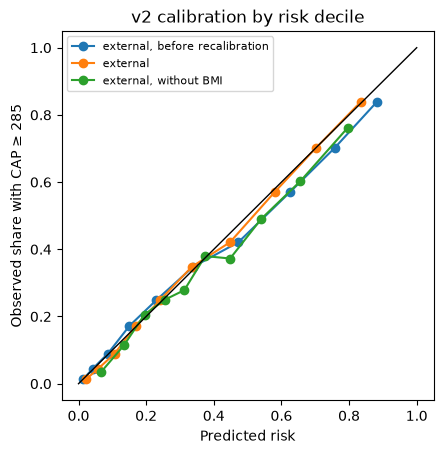

In [7]:
table, curves = {}, {}
for label, frame, kwargs in [("internal", internal, {}), ("external", external, {}),
                             ("external, before recalibration", external, {"raw_only": True}),
                             ("external, without BMI", external.assign(bmi=np.nan), {})]:
    table[label], curves[label] = calibration_summary(frame, predict(frame, **kwargs))
display(pd.DataFrame(table).T.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(4.8, 4.8))
for label in ["external, before recalibration", "external", "external, without BMI"]:
    ax.plot(curves[label]["predicted"], curves[label]["observed"], marker="o", label=label)
ax.plot([0, 1], [0, 1], color="black", linewidth=1)
ax.set(xlabel="Predicted risk", ylabel="Observed share with CAP ≥ 285", title="v2 calibration by risk decile")
ax.legend(fontsize=8)
plt.show()

## Risk bands for the Liver card

The card shows the risk and a band. Thresholds are chosen on the **internal** set (90%
sensitivity for "low", 90% specificity for "high") and checked on the external set.

In [8]:
p_internal, p_external = predict(internal), predict(external)
THRESHOLDS = {"low_below": threshold_for(internal, p_internal, sensitivity=0.9),
              "high_from": threshold_for(internal, p_internal, specificity=0.9)}
print(THRESHOLDS)
pd.DataFrame({
    f"low: risk < {THRESHOLDS['low_below']:.2f} (rule out)": weighted_rates(external, p_external, THRESHOLDS["low_below"]),
    f"high: risk ≥ {THRESHOLDS['high_from']:.2f} (rule in)": weighted_rates(external, p_external, THRESHOLDS["high_from"]),
}).T.style.format({"threshold": "{:.3f}", "flagged": "{:.1%}", "sensitivity": "{:.1%}", "specificity": "{:.1%}", "PPV": "{:.1%}", "NPV": "{:.1%}"})

{'low_below': np.float64(0.2085), 'high_from': np.float64(0.5894)}


,threshold,flagged,sensitivity,specificity,PPV,NPV
low: risk < 0.21 (rule out),0.208,57.9%,90.3%,58.8%,53.0%,92.2%
high: risk ≥ 0.59 (rule in),0.589,24.5%,53.9%,90.6%,74.8%,79.3%


"Flagged" is the share at or above the threshold. For the rule-out row, NPV is how often
"low" is right; for the rule-in row, PPV is how often "high" is right.

## Subgroups (external)

In [9]:
fmt = {"fatty liver": "{:.1%}", "AUROC": "{:.3f}", "mean predicted": "{:.1%}"}
display(subgroups(external, p_external).style.format(fmt).set_caption("v2 with BMI"))
subgroups(external, predict(external.assign(bmi=np.nan))).style.format(fmt).set_caption("v2 without BMI")

,adults,fatty liver,mean predicted,AUROC,95% CI
group,,,,,
sex: female,2992,29.7%,29.9%,0.860,0.843–0.875
sex: male,2533,38.3%,39.1%,0.835,0.812–0.856
race_ethnicity: Mexican American,396,42.0%,39.6%,0.837,0.791–0.887
race_ethnicity: Non-Hispanic Asian,326,30.3%,23.5%,0.817,0.753–0.870
race_ethnicity: Non-Hispanic Black,656,28.4%,37.8%,0.783,0.739–0.829
race_ethnicity: Non-Hispanic White,3216,34.8%,33.9%,0.872,0.855–0.888
race_ethnicity: Other Hispanic,565,33.9%,36.9%,0.852,0.797–0.892
race_ethnicity: Other/Multiracial,366,29.4%,35.5%,0.810,0.758–0.861
age_band: 18–39,1635,25.4%,26.1%,0.886,0.864–0.906


,adults,fatty liver,mean predicted,AUROC,95% CI
group,,,,,
sex: female,2992,29.7%,31.1%,0.793,0.774–0.812
sex: male,2533,38.3%,42.6%,0.742,0.714–0.767
race_ethnicity: Mexican American,396,42.0%,40.7%,0.762,0.705–0.813
race_ethnicity: Non-Hispanic Asian,326,30.3%,35.9%,0.781,0.719–0.846
race_ethnicity: Non-Hispanic Black,656,28.4%,37.1%,0.698,0.642–0.762
race_ethnicity: Non-Hispanic White,3216,34.8%,35.9%,0.789,0.769–0.810
race_ethnicity: Other Hispanic,565,33.9%,38.9%,0.771,0.706–0.820
race_ethnicity: Other/Multiracial,366,29.4%,38.2%,0.710,0.639–0.787
age_band: 18–39,1635,25.4%,27.4%,0.790,0.760–0.819


## Missing tests (external)

In [10]:
def blank(d, columns):
    return d.assign(**{c: np.nan for c in columns})


scenarios = {
    "everything": external,
    "no BMI": blank(external, ["bmi"]),
    "liver labs + BMI only (no metabolic labs)": blank(external, METABOLIC),
    "CMP + BMI (no GGT, lipids, HbA1c)": blank(external, ["GGT", "Triglycerides", "HDL Cholesterol", "Hemoglobin A1c", "Platelets"]),
    "AST + ALT + age + sex only": blank(external, [c for c in COLUMNS if c not in ("AST", "ALT", "age", "male")]),
}
pd.DataFrame({name: {"AUROC": weighted_auc(d, predict(d))} for name, d in scenarios.items()}).T.style.format("{:.3f}")

,AUROC
everything,0.849
no BMI,0.770
liver labs + BMI only (no metabolic labs),0.836
"CMP + BMI (no GGT, lipids, HbA1c)",0.830
AST + ALT + age + sex only,0.673


## Which inputs matter (external)

In [11]:
importance = permutation_importance(model, external[COLUMNS], external["fatty_liver"], scoring="roc_auc",
                                    sample_weight=external["weight"], n_repeats=10, random_state=0)
pd.DataFrame({"AUROC drop": importance.importances_mean}, index=COLUMNS).sort_values("AUROC drop", ascending=False).style.format("{:.3f}")

,AUROC drop
bmi,0.169
Hemoglobin A1c,0.015
GGT,0.013
ALT,0.011
Triglycerides,0.008
HDL Cholesterol,0.006
age,0.005
Uric Acid,0.003
Platelets,0.002
Albumin/Globulin Ratio,0.001


## Export to the backend

The backend loads `model.joblib` and `metadata.json` (see `backend/models/trained.py`). The
metadata records each input's registry unit so the loader can refuse a model if the registry
changes underneath it, plus the calibration, risk bands and the metrics above.

In [12]:
OUT = ML_DIR.parent / "backend" / "models" / "trained" / "liver_fatty_liver" / "v2"
OUT.mkdir(parents=True, exist_ok=True)
joblib.dump(model, OUT / "model.joblib")
auc = lambda name, label: round(float(discrimination.loc[name, ("AUROC", label)]), 3)
ci = lambda name, label: discrimination.loc[name, ("95% CI", label)]
ext_sub = subgroups(external, p_external, n_boot=50)
metadata = {
    "name": "Fatty liver risk",
    "model_version": "nhanes-liver-v2",
    "panel": "liver",
    "panel_schema_version": PANELS["liver"]["schema_version"],
    "features": COLUMNS,
    "feature_units": {c: BIOMARKERS[c]["unit"] for c in COLUMNS if c in BIOMARKERS},
    "patient_features": {"age": "years", "male": "1 if male else 0", "bmi": "kg/m2"},
    "required": ["ALT", "age", "male"],
    "calibration": {"method": "platt", **PLATT},
    "thresholds": {k: round(float(v), 4) for k, v in THRESHOLDS.items()},
    "label": "Elastography CAP >= 285 dB/m",
    "training_data": "NHANES 2017-March 2020 adults with a complete elastography exam",
    "training_rows": int(len(fit_set)), "calibration_rows": int(len(calibration_set)),
    "metrics": {
        "external_auroc": auc("v2 (with BMI)", "external"), "external_auroc_ci": ci("v2 (with BMI)", "external"),
        "external_auroc_without_bmi": auc("v2 without BMI", "external"),
        "internal_auroc": auc("v2 (with BMI)", "internal"),
        "external_calibration_slope": round(float(table["external"]["calibration slope"]), 3),
        "external_calibration_error": round(float(table["external"]["expected calibration error"]), 3),
    },
    "subgroup_mean_predicted_vs_observed": {g: [round(float(r["mean predicted"]), 3), round(float(r["fatty liver"]), 3)]
                                            for g, r in ext_sub.iterrows()},
    "sklearn_version": sklearn_version,
}
(OUT / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
print(f"{(OUT / 'model.joblib').stat().st_size / 1024:.0f} KB model")
print(json.dumps(metadata["metrics"], indent=2))

471 KB model
{
  "external_auroc": 0.849,
  "external_auroc_ci": "0.836\u20130.861",
  "external_auroc_without_bmi": 0.77,
  "internal_auroc": 0.85,
  "external_calibration_slope": 1.044,
  "external_calibration_error": 0.01
}


## Verdict

- **Much better than v1.** External AUROC rises from 0.73 to **0.85** with BMI — on par with the
  published Fatty Liver Index (which also needs a waist measurement) and above HSI — and holds up on
  the independent 2021–2023 cycle.
- **Risks can be shown as percentages.** After recalibration the external calibration slope is
  ≈ 1.0 and predicted risk is within about a percentage point of observed on average.
- **Height and weight are worth asking for.** Without BMI, v2 falls to ≈ 0.77 — still better than
  v1 thanks to the metabolic labs — and the card should say entering them improves the estimate.
- **Bands:** "low" is right about 9 times in 10; "high" about 3 times in 4.
- **Known gaps:** it over-predicts for Non-Hispanic Black adults and under-predicts for
  Non-Hispanic Asian adults, consistent with known differences in how BMI relates to liver fat.
  Race isn't (and shouldn't be) an input from a lab report, so this is stated as a limitation.
  It's also less accurate over age 60.
- **Still a screen.** CAP ≥ 285 dB/m is an imaging estimate of liver fat, NHANES is a US sample, and
  the result is not a diagnosis.